In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


In [3]:
class KMeansScratch:

    def __init__(self, k=3, max_iters=100, tol=1e-4, random_state=None):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.random_state = random_state

        self.centroids = None
        self.labels = None
        self.inertia_ = None
        self.n_iters_ = 0

    # --------------------------------------------------------
    # Step 1: Initialize centroids
    # --------------------------------------------------------

    def initialize_centroids(self, X):

        rng = np.random.default_rng(self.random_state)

        # Randomly choose k different data points
        indices = rng.choice(len(X), size=self.k, replace=False)

        return X[indices].copy()

    # --------------------------------------------------------
    # Step 2: Calculate Euclidean distance
    # --------------------------------------------------------

    def calculate_distances(self, X, centroids):

        # X shape:
        # (number_of_samples, number_of_features)
        #
        # centroids shape:
        # (k, number_of_features)

        distances = np.sqrt(
            np.sum(
                (X[:, np.newaxis] - centroids[np.newaxis, :]) ** 2,
                axis=2
            )
        )

        return distances

    # --------------------------------------------------------
    # Step 3: Assign points to nearest centroid
    # --------------------------------------------------------

    def assign_clusters(self, X, centroids):

        distances = self.calculate_distances(X, centroids)

        # Find index of nearest centroid
        labels = np.argmin(distances, axis=1)

        return labels

    # --------------------------------------------------------
    # Step 4: Recalculate centroids
    # --------------------------------------------------------

    def update_centroids(self, X, labels, old_centroids):

        new_centroids = np.zeros_like(old_centroids)

        for i in range(self.k):

            # Get all points belonging to cluster i
            cluster_points = X[labels == i]

            if len(cluster_points) > 0:
                new_centroids[i] = np.mean(cluster_points, axis=0)

            else:
                # If a cluster gets no points,
                # keep its old centroid
                new_centroids[i] = old_centroids[i]

        return new_centroids

    # --------------------------------------------------------
    # Step 5: Calculate WCSS / Inertia
    # --------------------------------------------------------

    def calculate_inertia(self, X, labels, centroids):

        inertia = 0

        for i in range(self.k):

            cluster_points = X[labels == i]

            if len(cluster_points) > 0:

                distances_squared = np.sum(
                    (cluster_points - centroids[i]) ** 2,
                    axis=1
                )

                inertia += np.sum(distances_squared)

        return inertia

    # --------------------------------------------------------
    # Step 6: Train K-Means
    # --------------------------------------------------------

    def fit(self, X):

        X = np.asarray(X, dtype=float)

        # Initialize centroids
        centroids = self.initialize_centroids(X)

        for iteration in range(self.max_iters):

            # Assign points to clusters
            labels = self.assign_clusters(X, centroids)

            # Calculate new centroids
            new_centroids = self.update_centroids(
                X,
                labels,
                centroids
            )

            # Check convergence
            centroid_shift = np.sqrt(
                np.sum((new_centroids - centroids) ** 2)
            )

            centroids = new_centroids

            self.n_iters_ = iteration + 1

            if centroid_shift < self.tol:
                break

        # Store final results
        self.centroids = centroids
        self.labels = self.assign_clusters(X, centroids)

        self.inertia_ = self.calculate_inertia(
            X,
            self.labels,
            self.centroids
        )

        return self

    # --------------------------------------------------------
    # Predict cluster for new data
    # --------------------------------------------------------

    def predict(self, X):

        X = np.asarray(X, dtype=float)

        return self.assign_clusters(
            X,
            self.centroids
        )

    # --------------------------------------------------------
    # Fit + Predict
    # --------------------------------------------------------

    def fit_predict(self, X):

        self.fit(X)

        return self.labels


In [4]:
# ============================================================
# 2. CREATE TEST DATA
# ============================================================

X, y_true = make_blobs(
    n_samples=500,
    centers=4,
    n_features=2,
    cluster_std=1.2,
    random_state=42
)


In [ ]:
# ============================================================
# 3. STANDARDIZE DATA
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


In [6]:
# ============================================================
# 4. ELBOW METHOD
# ============================================================

k_values = range(1, 11)

inertias = []

for k in k_values:

    model = KMeansScratch(
        k=k,
        max_iters=100,
        tol=1e-4,
        random_state=42
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)



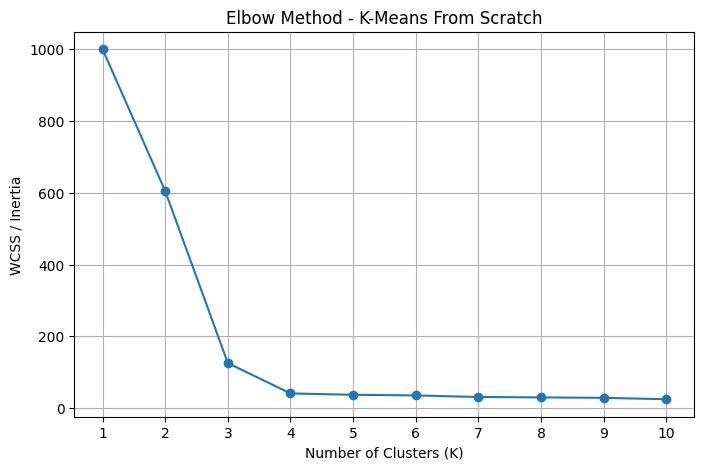

In [ ]:
# Plot Elbow curve

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method - K-Means From Scratch")

plt.xticks(k_values)
plt.grid(True)

plt.show()


In [8]:

# ============================================================
# 5. CHOOSE BEST K
# ============================================================

# From the elbow plot, choose K.

best_k = 4


In [ ]:

# ============================================================
# 6. TRAIN FINAL MODEL
# ============================================================

kmeans_scratch = KMeansScratch(
    k=best_k,
    max_iters=100,
    tol=1e-4,
    random_state=42
)

labels_scratch = kmeans_scratch.fit_predict(X_scaled)


print("K-Means From Scratch")
print("--------------------")

print("K:", best_k)
print("Iterations:", kmeans_scratch.n_iters_)
print("Inertia:", kmeans_scratch.inertia_)

print("\nCentroids:")
print(kmeans_scratch.centroids)


K-Means From Scratch
--------------------
K: 4
Iterations: 6
Inertia: 40.84677702589177

Centroids:
[[ 1.530125   -0.15455934]
 [ 0.14471277  0.97468641]
 [-0.68446254 -1.53954638]
 [-0.99037523  0.71941932]]


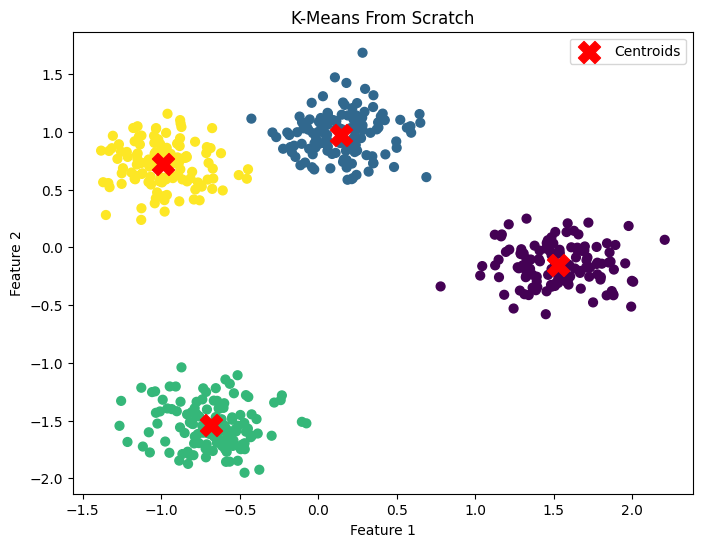

In [ ]:
# ============================================================
# 7. VISUALIZE SCRATCH IMPLEMENTATION
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_scratch,
    cmap="viridis",
    s=40
)

plt.scatter(
    kmeans_scratch.centroids[:, 0],
    kmeans_scratch.centroids[:, 1],
    c="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means From Scratch")

plt.legend()
plt.show()


In [ ]:
# ============================================================
# 8. TEST AGAINST SKLEARN
# ============================================================

sklearn_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

labels_sklearn = sklearn_model.fit_predict(X_scaled)


print("\n\nScikit-Learn K-Means")
print("--------------------")

print("K:", best_k)
print("Iterations:", sklearn_model.n_iter_)
print("Inertia:", sklearn_model.inertia_)




Scikit-Learn K-Means
--------------------
K: 4
Iterations: 2
Inertia: 40.84677702589176


In [ ]:

# ============================================================
# 9. COMPARE INERTIA
# ============================================================

print("\n\nComparison")
print("--------------------")

print(
    "Scratch Inertia :",
    kmeans_scratch.inertia_
)

print(
    "Sklearn Inertia :",
    sklearn_model.inertia_
)

print(
    "Difference      :",
    abs(
        kmeans_scratch.inertia_
        - sklearn_model.inertia_
    )
)




Comparison
--------------------
Scratch Inertia : 40.84677702589177
Sklearn Inertia : 40.84677702589176
Difference      : 7.105427357601002e-15


In [ ]:
# ============================================================
# 10. PREDICT NEW DATA
# ============================================================

new_points = np.array([
    [0, 0],
    [2, 2],
    [-2, -2]
])

new_points_scaled = scaler.transform(new_points)

predictions = kmeans_scratch.predict(
    new_points_scaled
)

print("\nNew Data Predictions")
print("--------------------")

for point, cluster in zip(new_points, predictions):

    print(
        f"Point {point} -> Cluster {cluster}"
    )



New Data Predictions
--------------------
Point [0 0] -> Cluster 0
Point [2 2] -> Cluster 0
Point [-2 -2] -> Cluster 2
